In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

from src.config import PROCESSED_DATA_PATH, FIGURES_DIR



sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Завантажуємо вітрину даних 
df = pd.read_csv(PROCESSED_DATA_PATH)

print(f"Розмірність вітрини: {df.shape}")
print(f"Дублікатів customerID: {df['customerID'].duplicated().sum()}")
print("\nКількість пропусків по колонках:")
missing = df.isna().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Пропусків немає (0)")

df.head()

Розмірність вітрини: (7043, 26)
Дублікатів customerID: 0

Кількість пропусків по колонках:
Пропусків немає (0)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,tenure_group,active_addons_count,PhoneService,MultipleLines,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,charge_to_contract_avg_ratio,diff_from_internet_avg,charge_pct_rank_in_contract,Churn
0,3797-VTIDR,Male,0,Yes,No,1,0-12m,0,No,No phone service,...,No,Month-to-month,Yes,Electronic check,23.45,23.45,0.353,-34.65,0.124,1
1,6834-NXDCA,Female,0,No,No,13,12-24m,0,No,No phone service,...,No,Month-to-month,Yes,Electronic check,23.90,300.80,0.360,-34.20,0.124,1
2,2346-DJQTB,Female,0,No,No,35,24-48m,0,No,No phone service,...,No,Month-to-month,No,Electronic check,24.15,812.50,0.364,-33.95,0.126,0
3,5351-QESIO,Male,0,No,Yes,1,0-12m,0,No,No phone service,...,No,Month-to-month,No,Mailed check,24.20,24.20,0.364,-33.90,0.126,0
4,5650-VDUDS,Female,0,No,No,4,0-12m,0,No,No phone service,...,No,Month-to-month,Yes,Mailed check,24.25,96.05,0.365,-33.85,0.126,1


У першій комірці коду проаналізували якість даних. Бачимо, що Не має повторів, пропусків. Можемо переходити до наступних етапів досліджень.

Клас 0: 5174 клієнтів (73.46%)
Клас 1: 1869 клієнтів (26.54%)


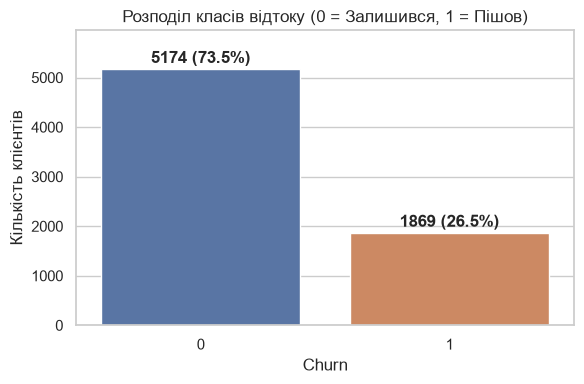

In [2]:
churn_counts = df["Churn"].value_counts()
churn_pct = df["Churn"].value_counts(normalize=True) * 100

for label in [0, 1]:
    print(f"Клас {label}: {churn_counts[label]} клієнтів ({churn_pct[label]:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=churn_counts.index,
    y=churn_counts.values,
    hue=churn_counts.index,
    palette=["#4C72B0", "#DD8452"],
    legend=False,
    ax=ax
)
ax.set_title("Розподіл класів відтоку (0 = Залишився, 1 = Пішов)")
ax.set_xlabel("Churn")
ax.set_ylabel("Кількість клієнтів")
ax.set_ylim(0, churn_counts.max() * 1.15)

for i, v in enumerate(churn_counts.values):
    ax.text(i, v + 120, f"{v} ({churn_pct[i]:.1f}%)", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

Поділили клієнтів на два класи 0 - клієнт продовжує користуватись послугами компанії, 1 - клієнт припинив користуватись послугами компанії. Бачимо, що 26% клієнтів компанія втратила.

In [3]:
cat_cols = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure_group",
    "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV",
    "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"
]

chi2_results = []
for col in cat_cols:
    contingency = pd.crosstab(df[col], df["Churn"])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    chi2_results.append({
        "Feature": col,
        "Chi2_stat": round(chi2_stat, 2),
        "p_value": p_val,
        "Significant (p < 0.05)": p_val < 0.05
    })

chi2_df = pd.DataFrame(chi2_results).sort_values("Chi2_stat", ascending=False)
display(chi2_df)

,Feature,Chi2_stat,p_value,Significant (p < 0.05)
14,Contract,1184.60,5.863038e-258,True
4,tenure_group,868.86,9.286900e-187,True
8,OnlineSecurity,850.00,2.661150e-185,True
11,TechSupport,828.20,1.443084e-180,True
7,InternetService,732.31,9.571788e-160,True
16,PaymentMethod,648.14,3.682355e-140,True
9,OnlineBackup,601.81,2.079759e-131,True
10,DeviceProtection,558.42,5.505219e-122,True
13,StreamingMovies,375.66,2.667757e-82,True
12,StreamingTV,374.20,5.528994e-82,True


Маємо 17 категоріальних ознак. Визначивши Chi2 перевіряємо, залежність цільової зміної Churn від конкретної ознаки(Чим більше значення, тим сильніший зв'язок). На основі Chi2 рахуємо p-value кожної ознаки та можемо віділити ознаки, що статистично впливають на відток клієнтів Churn(мають значення True у таблиці), а які ні(мають значення False).

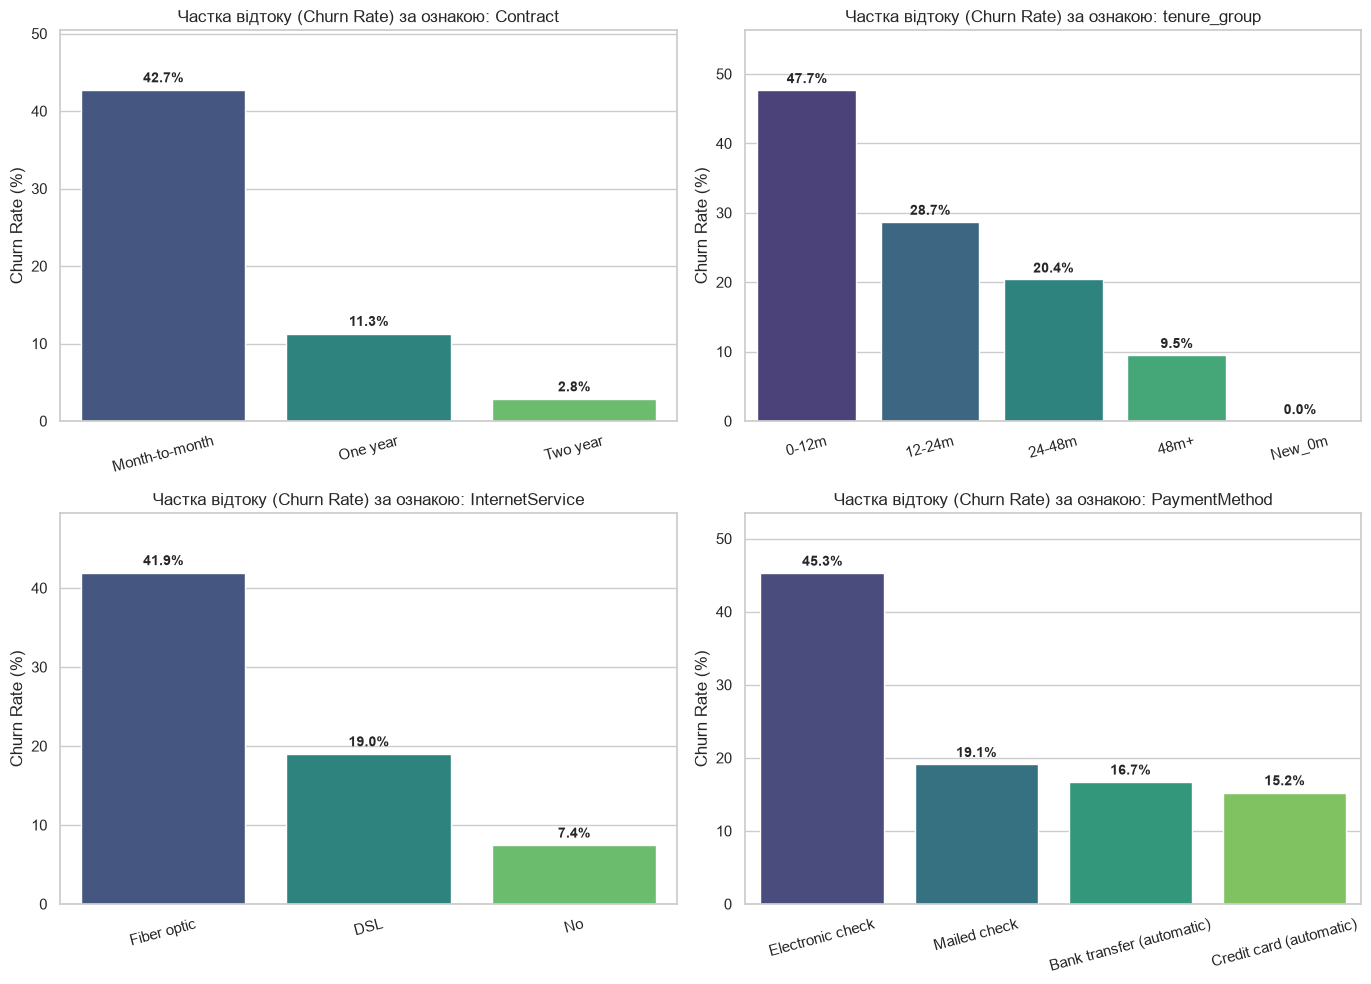

In [4]:
top_cats = ["Contract", "tenure_group", "InternetService", "PaymentMethod"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, col in enumerate(top_cats):
    churn_rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(
        x=churn_rate.index,
        y=churn_rate.values,
        hue=churn_rate.index,
        palette="viridis",
        legend=False,
        ax=axes[idx]
    )
    axes[idx].set_title(f"Частка відтоку (Churn Rate) за ознакою: {col}")
    axes[idx].set_ylabel("Churn Rate (%)")
    axes[idx].set_xlabel("")
    axes[idx].set_ylim(0, churn_rate.max() * 1.18)
    axes[idx].tick_params(axis="x", rotation=15)

    for i, v in enumerate(churn_rate.values):
        axes[idx].text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

Ми вже показали у попередньому пункті ознаки від яких залежить відток клієнтів. Візуалізуємо цей зв'язок на найбільш показових чотирьох. Бачимо, що клієнти з помісячним контрактом, які користуються послугами компанії до року, користуються електронним чеком та підключили оптоволоконний інтернет найчастіше припиняють користуватись послугами компанії.(в цьому речі коми варто всприймати як логічне АБО)

In [6]:
num_cols = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "active_addons_count",
    "charge_to_contract_avg_ratio",
    "diff_from_internet_avg",
    "charge_pct_rank_in_contract"
]

mw_results = []
for col in num_cols:
    group_stay = df[df["Churn"] == 0][col]
    group_churn = df[df["Churn"] == 1][col]

    stat, p_val = mannwhitneyu(group_stay, group_churn, alternative="two-sided")
    mw_results.append({
        "Feature": col,
        "Median_Stay (0)": round(group_stay.median(), 3),
        "Median_Churn (1)": round(group_churn.median(), 3),
        "p_value": p_val,
        "Significant (p < 0.05)": p_val < 0.05
    })

mw_df = pd.DataFrame(mw_results).sort_values("p_value")
display(mw_df)

,Feature,Median_Stay (0),Median_Churn (1),p_value,Significant (p < 0.05)
0,tenure,38.000,10.00,2.419636e-208,True
2,TotalCharges,1679.525,703.55,5.685034e-83,True
5,diff_from_internet_avg,-0.530,-4.60,5.012494e-72,True
1,MonthlyCharges,64.425,79.65,3.311628e-54,True
6,charge_pct_rank_in_contract,0.448,0.61,9.199263e-48,True
4,charge_to_contract_avg_ratio,0.996,1.20,4.766157e-38,True
3,active_addons_count,2.000,2.00,4.735235e-07,True


Раніше ми визначили серед категоріальних ознак ті, що впливають на цільову змінну. Знайдемо такі серед числових. Нагадую розподіл всіх лідів по класах: 0 - клієнти компанії, 1 - припинили користуватись послугами. В цьому випадку обчислюємо p-value на основі U-критерію Манна-Уїтні. Бачимо, що всі 7 ознак є значущими. 

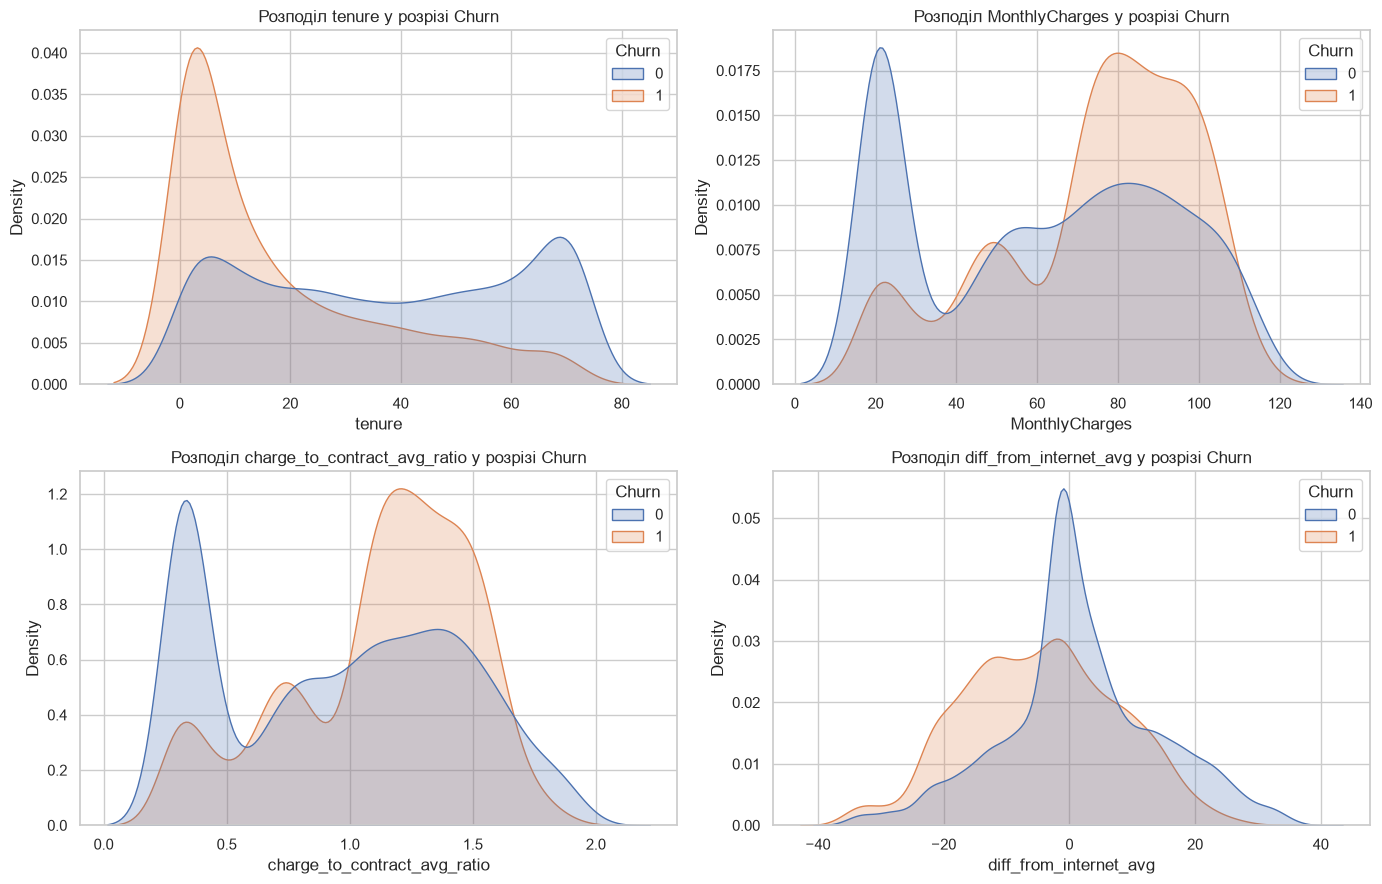

In [7]:
plot_nums = [
    "tenure",
    "MonthlyCharges",
    "charge_to_contract_avg_ratio",
    "diff_from_internet_avg"
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for idx, col in enumerate(plot_nums):
    sns.kdeplot(
        data=df,
        x=col,
        hue="Churn",
        fill=True,
        common_norm=False,
        palette=["#4C72B0", "#DD8452"],
        ax=axes[idx]
    )
    axes[idx].set_title(f"Розподіл {col} у розрізі Churn")

plt.tight_layout()
plt.show()

Бачимо 4 графіки ядерної оцінки щільності розподілу (KDE — Kernel Density Estimation), щоб візуально порівняти форму розподілу ключових та показових числових ознак між клієнтами, які залишилися, та тими, хто пішов. Графіки зроблені по двом базовим змінним: tenure, MonthlyCharges та двом створеними нами раніше ознак: charge_to_contract_avg_ratio, diff_from_internet_avg. 

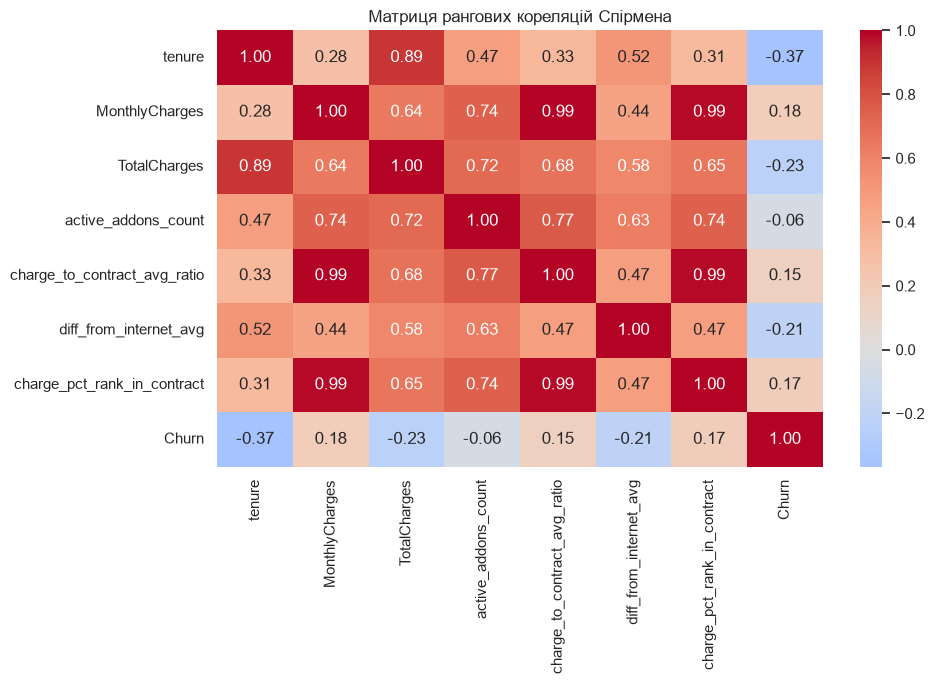

In [8]:
plt.figure(figsize=(10, 7))
corr_matrix = df[num_cols + ["Churn"]].corr(method="spearman")
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Матриця рангових кореляцій Спірмена")
plt.tight_layout()
plt.show()

Бачимо матрицю рангових кореляцій Спірмена у вигляді теплової карти, щоб оцінити силу зв'язку числових ознак із відтоком (Churn) та виявити мультиколінеарність (сильну взаємозалежність) між самими предикторами.

Вплив предикторів на цільову змінну:
Найсильніший зворотний зв'язок із відтоком демонструє стаж клієнта (tenure, $-0.37$), що підтверджує суттєве зниження ризику втрати абонента зі збільшенням тривалості співпраці. 
Помірну зворотну кореляцію також показують накопичені витрати (TotalCharges, $-0.23$) та різниця із середнім платежем за типом інтернету (diff_from_internet_avg, $-0.21$).   
Прямий зв'язок із відтоком мають поточні цінові характеристики: щомісячний рахунок (MonthlyCharges, $0.18$), процентильний ранг у контракті (charge_pct_rank_in_contract, $0.17$) та відношення платежу до середнього чека контракту (charge_to_contract_avg_ratio, $0.15$). Зростання регулярного фінансового навантаження підвищує схильність клієнтів до припинення обслуговування.   
Кількість підключених додаткових опцій (active_addons_count, $-0.06$) виявляє слабкий монотонний зв'язок із утриманням клієнтів.   

Мультиколінеарність між ознаками 
Показники MonthlyCharges, charge_to_contract_avg_ratio та charge_pct_rank_in_contract демонструють майже функціональну взаємозалежність ($0.99$), оскільки описують ідентичне цінове ранжування в межах тарифних сегментів.   
Висока кореляція між стажем tenure та загальними витратами TotalCharges ($0.89$) зумовлена кумулятивним накопиченням платежів протягом усього життєвого циклу клієнта.   
Кількість активних сервісів (active_addons_count) тісно пов'язана з усіма монетарними метриками ($0.72\text{–}0.77$), виступаючи прямим драйвером формування чека.   

З огляду на виявлену мультиколінеарність ($0.89\text{–}0.99$), під час побудови лінійних моделей необхідно застосовувати методи регуляризації ($L1$/$L2$) для стабілізації ваг ознак, тоді як алгоритми на основі дерев рішень зможуть використовувати ці змінні без втрати стійкості. Окрему аналітичну цінність зберігає показник diff_from_internet_avg, який має помірну кореляцію з іншими предикторами ($0.44\text{–}0.63$) та надає моделі незалежний сигнал про цінову чутливість абонента.   

Тип контракту — найсильніший предиктор: клієнти на помісячному тарифі (Month-to-month) йдуть у ~42.7% випадків, тоді як на дворічному контракті (Two year) відтік становить менше 3%.

Критичний поріг стажу: медіанний стаж клієнтів, що пішли (tenure), становить 10 місяців проти 38 місяців у лояльної бази.

charge_to_contract_avg_ratio та diff_from_internet_avg показали статистично значущу різницю ($p < 0.05$) — клієнти, чий чек перевищує середній по їхньому контракту або типу інтернету, мають вищий ризик відтоку.

Статистично незначущі ознаки: gender та PhoneService мають $p > 0.05$ і практично не несуть сигналу про відтік.